# Modeling and seeing what phrases and words that distinctibly identify the varieties

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sentence_transformers import SentenceTransformer

df = pd.read_pickle("processed_reviews.pkl")
df = df[df["variety"].notna()].reset_index(drop=True)
print(f"Shape: {df.shape}")
print("-"*1000)
print(df.info())

KeyboardInterrupt: 

In [ ]:
variety_counts = df["variety"].value_counts()

for t in [50, 100, 150, 300, 500, 1000]:
    keep = variety_counts[variety_counts >= t]
    print(f">= {t:>5}: {len(keep):>3} varieties | {keep.sum() / len(df):.1%} of reviews")


>=    50: 149 varieties | 96.9% of reviews
>=   100:  99 varieties | 94.8% of reviews
>=   150:  81 varieties | 93.5% of reviews
>=   300:  54 varieties | 90.0% of reviews
>=   500:  43 varieties | 87.4% of reviews
>=  1000:  34 varieties | 83.5% of reviews


In [ ]:
grape_counts = df.loc[df["in_target"], "grape"].value_counts()


bucket_edges = [0, 150, 500, 1000, 2000, 5000, np.inf]
bucket_labels = ["Other", "150-499", "500-999", "1000-1999", "2000-4999", "5000+"]

grape_bucket = pd.cut(grape_counts, bins=bucket_edges, labels=bucket_labels, right=False) # creating the bucketize maping/ schema for the grape

df["bucket"] = df["variety"].map(grape_bucket) # creating the bucketized variety

In [ ]:
bucket_summary = (df.groupby("bucket", observed=True)
                    .agg(varieties=("variety", "nunique"),
                         reviews=("variety", "size"))
                    .assign(pct_reviews=lambda d: (100 * d["reviews"] / d["reviews"].sum()).round(1)))
bucket_summary

,varieties,reviews,pct_reviews
bucket,,,
Other,675,11023,6.5
150-499,38,10290,6.1
500-999,9,6684,3.9
1000-1999,16,22683,13.4
2000-4999,10,33834,19.9
5000+,8,85098,50.2


In [ ]:
EMB_PATH = Path("embeddings_minilm_masked.npy")
encoder = SentenceTransformer("all-MiniLM-L6-v2") # popular embedding model used for comparing similar sentences

if EMB_PATH.exists():
    embeddings = np.load(EMB_PATH)
else:
    embeddings = encoder.encode(df["description_masked"].tolist(), batch_size=256, normalize_embeddings=True, show_progress_bar=True)
    np.save(EMB_PATH, embeddings)

print(embeddings.shape)

(169612, 384)


# Prototype per variety

In [ ]:
is_train = (df["split"] == "train").to_numpy()
named = df["in_target"].to_numpy()

train_emb = embeddings[is_train & named] # grabs all trained data along with all varieties that aren't other
train_labels = df.loc[is_train & named, "grape"].to_numpy() # grabs the traning labels of ever training and variety label. 

global_mean = embeddings[is_train].mean(axis=0)
centered = train_emb - global_mean # calculates the centroid to be ready for cosine similarity

prototypes = pd.DataFrame(centered).groupby(train_labels).mean() # all centered or centroid of each vector is grouped with their label
proto = prototypes.to_numpy() # turned into a matrix or numpy
proto = proto / np.linalg.norm(proto, axis=1, keepdims=True) # Using L2 normalizes each prototype to unit length


# proto @ prot.T is dot product
sim = (pd.DataFrame(proto @ proto.T, index=prototypes.index, columns=prototypes.index)
         .rename_axis(index="variety_a", columns="variety_b")) # calculates the similarities 
sim.index.name, sim.columns.name = "variety_a", "variety_b" # for later reference


# Visualy seeing which varieites are simlar to each other

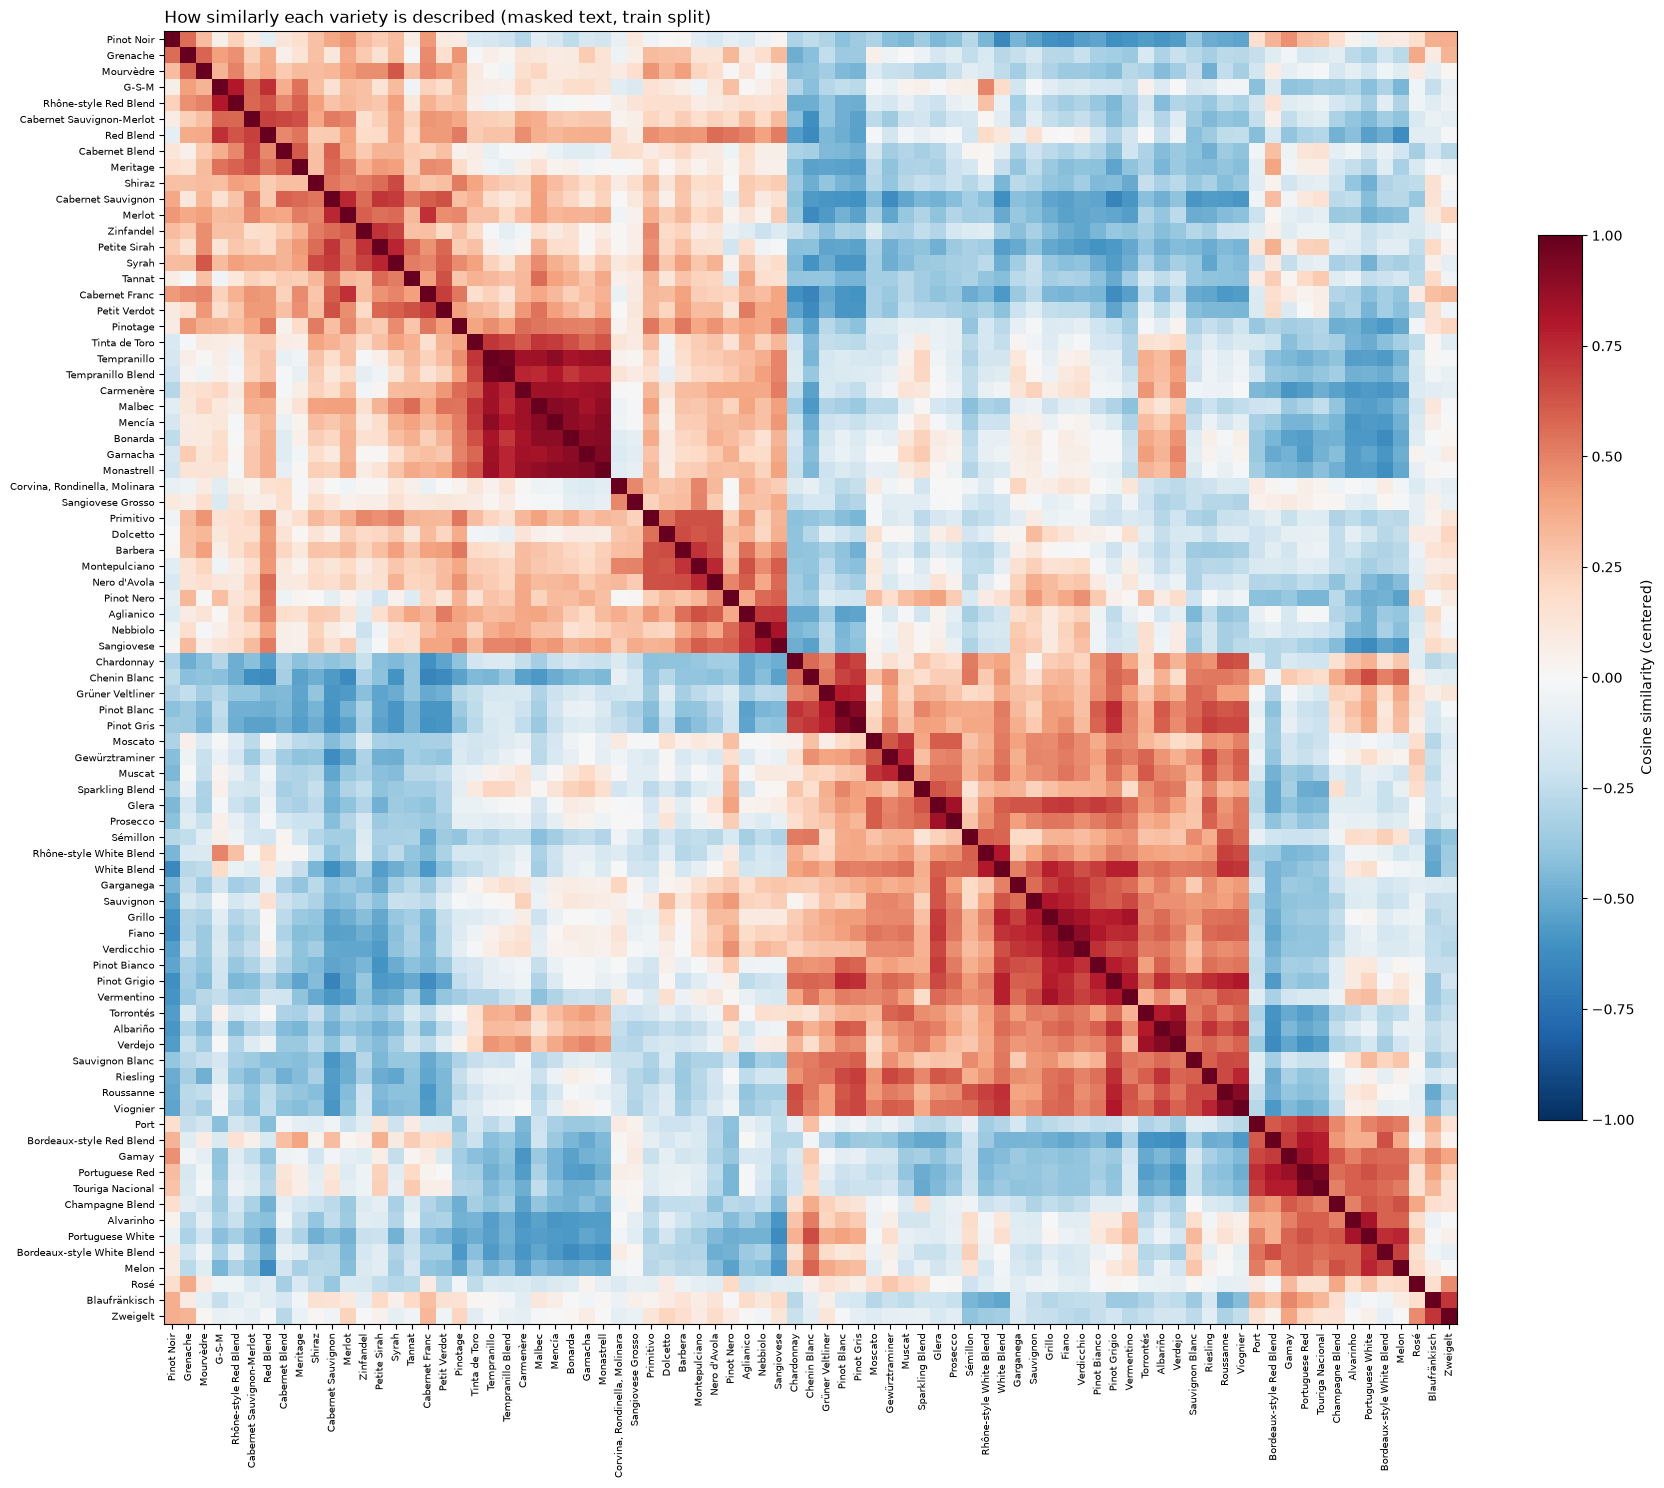

In [ ]:
dist = np.clip(1 - sim.to_numpy(), 0, None)
np.fill_diagonal(dist, 0)
order = leaves_list(linkage(squareform(dist, checks=False), method="average"))
sim_ordered = sim.iloc[order, order]

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(sim_ordered, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sim_ordered)), sim_ordered.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(sim_ordered)), sim_ordered.index, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.6, label="Cosine similarity (centered)")
ax.set_title("How similarly each variety is described (masked text, train split)", loc="left")
plt.tight_layout()
plt.show()


In [ ]:
upper = np.triu(np.ones(sim.shape, dtype=bool), k=1)
pairs = sim.where(upper).stack().dropna().rename("cosine").reset_index()
pairs["bucket_a"] = pairs["variety_a"].map(grape_bucket)
pairs["bucket_b"] = pairs["variety_b"].map(grape_bucket)

pairs.nlargest(25, "cosine")

pairs.sort_values("cosine", ascending=False).to_csv("variety_cosine_pairs.csv", index=False, encoding="utf-8-sig")

display(pairs)

,variety_a,variety_b,cosine,bucket_a,bucket_b
0,Aglianico,Albariño,-0.171992,150-499,500-999
1,Aglianico,Alvarinho,-0.350498,150-499,150-499
2,Aglianico,Barbera,0.550033,150-499,500-999
3,Aglianico,Blaufränkisch,0.183415,150-499,150-499
4,Aglianico,Bonarda,0.247734,150-499,150-499
...,...,...,...,...,...
3235,Viognier,Zinfandel,-0.199877,1000-1999,2000-4999
3236,Viognier,Zweigelt,-0.249942,1000-1999,150-499
3237,White Blend,Zinfandel,-0.340863,2000-4999,2000-4999
3238,White Blend,Zweigelt,-0.345847,2000-4999,150-499


# Analysis
The heatmap is a great way for us to narrow down our analysis. Many variety types of wine share common descriptions. For example, Temparanillo and Tempranillo Blend have similar descriptions because they likely have simlar if not the same ingredients used in both varieties of wine. Explains why the cosine similarity is high. This is can be commonly seen with wine varieties that either have similar names with one another. 

Examples of wines that have different names but have a high cosine similarity are Garnacha and Monastrell and Albarino and Verdejo. They boast a 0.9254 and 0.924600 cosine similarity score respectively. This sets up our analysis later to further investigate what words and phrases make these varieties taste alike, and what makes the different. 

In [ ]:
from sklearn.preprocessing import LabelEncoder

include_other = True # if we want to change it any time 

model_df = df if include_other else df[df["variety_label"] != "Other"]
model_df = model_df[["review_id", "variety", "variety_label", "bucket", "grape", "split",
                     "description", "description_masked"]].copy()

model_df["emb_row"] = model_df.index
model_df = model_df.reset_index(drop=True)

label_encoder = LabelEncoder().fit(model_df["variety_label"])
model_df["y"] = label_encoder.transform(model_df["variety_label"]) # creating our target label and encoding
n_classes = len(label_encoder.classes_) # counting how many varieities there are

print(f"{len(model_df)} reviews | {n_classes} classes")


169612 reviews | 82 classes


In [ ]:
split_counts = pd.crosstab(model_df["variety_label"], model_df["split"])[["train", "val", "test"]]
split_counts["val_pct"] = (100 * split_counts["val"] / split_counts.sum(axis=1)).round(1)

print("Fewest reviews in any class per split:")
print(split_counts[["train", "val", "test"]].min())
split_counts.sort_values("train").head(10)

Fewest reviews in any class per split:
split
train    106
val       19
test      22
dtype: int64


split,train,val,test,val_pct
variety_label,,,,
Bonarda,106,23,22,15.2
Grillo,106,23,23,15.1
Monastrell,111,28,25,17.1
Alvarinho,114,19,27,11.9
Verdicchio,118,25,25,14.9
Fiano,124,27,26,15.3
Muscat,126,32,27,17.3
Pinot Bianco,129,27,27,14.8
Pinot Nero,134,27,38,13.6


In [ ]:
from sklearn.model_selection import train_test_split

train_val_idx, test_idx = train_test_split(model_df.index, test_size=0.15, stratify=model_df["y"], random_state=67)
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.15 / 0.85, stratify=model_df.loc[train_val_idx, "y"], random_state=67)

model_df.loc[train_idx, "split"] = "train"
model_df.loc[val_idx, "split"] = "val"
model_df.loc[test_idx, "split"] = "test"

In [ ]:
import re

def mentions_own_name(row):
    names = {row["variety"]}
    if isinstance(row["grape"], str):
        names.add(row["grape"])
    return any(re.search(rf"\b{re.escape(n)}\b", row["description"], flags=re.IGNORECASE)
               for n in names)

model_df["own_name_in_text"] = model_df.apply(mentions_own_name, axis=1)
model_df["any_name_in_text"] = model_df["description_masked"].str.contains("varietyname")

model_df.groupby("bucket", observed=True)[["own_name_in_text", "any_name_in_text"]].mean().round(3)


,own_name_in_text,any_name_in_text
bucket,,
Other,0.269,0.377
150-499,0.331,0.402
500-999,0.213,0.369
1000-1999,0.167,0.286
2000-4999,0.208,0.338
5000+,0.180,0.408


In [ ]:
raw_emb_path = Path("embeddings_minilm_raw.npy")

# Just incase the embeddings weren't saved
if raw_emb_path.exists():
    embeddings_raw = np.load(raw_emb_path)
else:
    embeddings_raw = encoder.encode(df["description"].tolist(), batch_size=256,
                                    normalize_embeddings=True, show_progress_bar=True)
    np.save(raw_emb_path, embeddings_raw)

emb_raw = embeddings_raw[model_df["emb_row"].to_numpy()]
emb_masked = embeddings[model_df["emb_row"].to_numpy()]
print(emb_raw.shape, emb_masked.shape)

(169612, 384) (169612, 384)


# Further understanding Comparing class-weighting schemes

In [ ]:
train_counts = np.bincount(model_df.loc[model_df["split"] == "train", "y"], minlength=n_classes)

def class_weights(counts, scheme="sqrt", beta=0.999):
    if scheme == "inverse":
        w = 1/counts
    elif scheme == "sqrt":
        w = 1/np.sqrt(counts)
    elif scheme == "effective":
        w = (1 - beta) / (1 - beta ** counts)
    return w * counts.sum() / (w * counts).sum()

weight_table = pd.DataFrame({
    "train_reviews": train_counts,
    "inverse": class_weights(train_counts, "inverse"),
    "sqrt": class_weights(train_counts, "sqrt"),
    "effective": class_weights(train_counts, "effective"),
}, index=label_encoder.classes_).round(2)

weight_table.sort_values("train_reviews")

,train_reviews,inverse,sqrt,effective
Bonarda,105,13.79,4.69,6.91
Grillo,106,13.66,4.66,6.85
Alvarinho,112,12.93,4.54,6.50
Monastrell,115,12.59,4.48,6.34
Verdicchio,118,12.27,4.42,6.19
...,...,...,...,...
Other,7716,0.19,0.55,0.69
Red Blend,7858,0.18,0.54,0.69
Cabernet Sauvignon,9292,0.16,0.50,0.69
Chardonnay,10948,0.13,0.46,0.69


In [ ]:
model_df.to_pickle("model_data.pkl")
pd.Series(label_encoder.classes_, name="variety_label").to_csv("label_classes.csv", index=False)
weight_table.to_csv("class_weights.csv")

In [ ]:
def get_split(name):
    part = model_df[model_df["split"] == name]
    rows = part["emb_row"].to_numpy()
    return part, embeddings_raw[rows], embeddings[rows], part["y"].to_numpy()

# Archite3cture of our Model Prototype 1:

```
                    ┌─ M1: TF-IDF (words + phrases) → Logistic Regression ─┐
review description ─┼─ M2: Doc2Vec embedding → LSTM (weighted CE / focal)   ─┼─→ combine probabilities → variety
                    └─ M3: MiniLM embedding → cosine to 82 prototypes     ─┘
```

| Model | Input | Method | Output |
|---|---|---|---|
| **M1** | TF-IDF (words + phrases) | Logistic Regression | Probability for each of the 82 varieties |
| **M2** | Doc2Vec embedding + word sequence | BiLSTM (RNN) utilizing Doc2Vec embeddings, weighted CE | Probability for each of the 82 varieties |
| **M3** | MiniLM embedding | Cosine similarity to 82 variety prototypes | Probability for each of the 82 varieties |

The three probability outputs are **combined** (weighted average tuned on `val`) to predict the final **variety**.


In [ ]:
import numpy as np
import pandas as pd
import torch
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, top_k_accuracy_score, log_loss

model_df = pd.read_pickle("model_data.pkl")
classes = pd.read_csv("label_classes.csv")["variety_label"].to_numpy()
weight_table = pd.read_csv("class_weights.csv", index_col=0)
embeddings_masked = np.load("embeddings_minilm_masked.npy")
embeddings_raw = np.load("embeddings_minilm_raw.npy")

n_classes = len(classes)
WEIGHT_SCHEME = "sqrt"
class_w = weight_table.loc[classes, WEIGHT_SCHEME].to_numpy()

print(f"{n_classes} classes | GPU available: {torch.cuda.is_available()}")


82 classes | GPU available: False


In [ ]:
def get_split(name):
    part = model_df[model_df["split"] == name]
    rows = part["emb_row"].to_numpy()
    return part, embeddings_raw[rows], embeddings_masked[rows], part["y"].to_numpy()

train, train_raw, train_masked, y_train = get_split("train")
val, val_raw, val_masked, y_val = get_split("val")
test, test_raw, test_masked, y_test = get_split("test")

print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

train 118,728 | val 25,442 | test 25,442


# Evaluation Function for all models

In [ ]:
results = []

def sub_f1(y, pred, mask): 
    return f1_score(y[mask], pred[mask], labels=np.unique(y[mask]), average="macro", zero_division=0)

def evaluate(name, part, proba, y): 
    pred = proba.argmax(axis=1)
    named = part["own_name_in_text"].to_numpy()

    row = {"model": name, 
           "macro_f1": f1_score(y, pred, average="macro"),
           "accuracy": accuracy_score(y, pred),
           "top3_acc": top_k_accuracy_score(y, proba, k=3, labels=np.arange(n_classes)),
           "f1_name_present": sub_f1(y, pred, named),
           "f1_name_abset": sub_f1(y, pred, ~named)
    }

    for bucket, idx in part.groupby("bucket", observed=True).indices.items():
        mask = np.zeros(len(part), dtype=bool)
        mask[idx] = True
        row[f"f1_{bucket}"] = sub_f1(y, pred, mask)

    results.append(row)
    return pd.Series(row)


# Model 1: TF-IDF --> Logistic Regression

In [ ]:
train_text = pd.concat([train["description"], train["description_masked"]], ignore_index=True) # concat the both description and masked
y_train_m1 = np.concatenate([y_train, y_train]) # Combining two class training --> one for normal and masked

word_vec = TfidfVectorizer(ngram_range=(1, 3), min_df=5, sublinear_tf=True) # check back and modify to 1,2 later if it'll improve
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True, max_features=300000)

X_train_m1 = hstack([word_vec.fit_transform(train_text), char_vec.fit_transform(train_text)]).tocsr()

def m1_features(text):
    return hstack([word_vec.transform(text), char_vec.transform(text)]).tocsr()

X_val_m1 = m1_features(val["description"])
X_test_m1 = m1_features(test["description"])
print(X_train_m1.shape)

(237456, 511278)


In [ ]:
m1 = LogisticRegression(C=1.0, max_iter=1000)
m1.fit(X_train_m1, y_train_m1, sample_weight=class_w[y_train_m1])

prob_val_m1 = m1.predict_log_proba(X_val_m1)
np.save("proba_val_m1.npy", prob_val_m1)
evaluate("M1: TF-IDF + LogReg", val, prob_val_m1, y_val)

model              M1: TF-IDF + LogReg
macro_f1                      0.488884
accuracy                      0.631672
top3_acc                      0.815895
f1_name_present                0.67562
f1_name_abset                  0.36944
f1_Other                       0.47417
f1_150-499                    0.434868
f1_500-999                    0.581206
f1_1000-1999                  0.731513
f1_2000-4999                  0.712667
f1_5000+                      0.785683
dtype: object

In [ ]:
import joblib

joblib.dump({"model": m1, "word_vec": word_vec, "char_vec": char_vec}, "m1_tfidf_logreg.joblib")

proba_test_m1 = m1.predict_proba(X_test_m1)
np.save("proba_test_m1.npy", proba_test_m1)


# Model 2: Doc2Vec + BiLSTM 

# Doc2Vec: 
Doc2Vec (Le & Mikolov, 2014, also called “Paragraph Vectors”) extends Word2Vec. Word2Vec learns a dense vector for each word by training a small neural network to predict words from their neighbors. Words used in similar contexts, like “doctor” and “physician”, end up with similar vectors.

**Two Variants** 
1. PV-DM (Distributed Memory). To predict the next word in a window, the model combines the surrounding word vectors with the document’s vector. The document vector acts as a memory of what the document is about, supplying context the local words don’t.
2. PV-DBOW (Distributed Bag of Words). The document vector alone is trained to predict words sampled from that document. It is simpler and faster, and often works as well or better.



In [ ]:
import os
import re
import time
import pandas as pd
import numpy as np
from pathlib import Path
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

SEED = 67
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize(text):
    return TOKEN_RE.findall(text.lower()) # tokenizeds and splits up all of the words 

train_tok_m2 = [tokenize(t) for t in pd.concat([train["description"], train["description_masked"]], ignore_index=True)] # tokenizes all of the words 
y_train_m2 = np.concatenate([y_train, y_train])
val_tok_m2 = [tokenize(t) for t in val["description"]]
test_tok_m2 = [tokenize(t) for t in test["description"]]

D2V_PATH = Path("m2_doc2vec.model")



# Just to make things easier this will save all tokenized words within description and masked. 
if D2V_PATH.exists():
    d2v = Doc2Vec.load(str(D2V_PATH)) 
else:
    tagged = [TaggedDocument(toks, [i]) for i, toks in enumerate(train_tok_m2)]
    d2v = Doc2Vec(vector_size=150, dm=0, dbow_words=1,
                  window=5, min_count=5, negative=5, sample=1e-4,
                  epochs=20, workers=os.cpu_count(), seed=SEED) # Doc2Vec 
    d2v.build_vocab(tagged)
    d2v.train(tagged, total_examples=len(tagged), epochs=d2v.epochs)
    d2v.save(str(D2V_PATH))

print(f"Doc2Vec vocab: {len(d2v.wv):,} words | vector size {d2v.vector_size}")


Doc2Vec vocab: 16,388 words | vector size 150


In [ ]:
def infer_doc_vectors(token_lists, path):
    path = Path(path)
    if path.exists():
        return np.load(path)
    vecs = np.vstack([d2v.infer_vector(toks, epochs=d2v.epochs) for toks in token_lists]).astype(np.float32)
    np.save(path, vecs)
    return vecs

train_doc_m2 = infer_doc_vectors(train_tok_m2, "m2_docvec_train.npy")
val_doc = infer_doc_vectors(val_tok_m2, "m2_docvec_val.npy")
test_doc = infer_doc_vectors(test_tok_m2, "m2_docvec_test.npy")

# Standardizing the doc_m2 vectors
doc_mean, doc_std = train_doc_m2.mean(axis=0), train_doc_m2.std(axis=0) + 1e-6
train_doc_m2, val_doc, test_doc = [(v - doc_mean) / doc_std for v in (train_doc_m2, val_doc, test_doc)] 

print(train_doc_m2.shape, val_doc.shape, test_doc.shape)


(237456, 150) (25442, 150) (25442, 150)


In [ ]:
# turns the tokenized words into numbers..... Neeed to do this for the RNN

MAX_LEN = 72
PAD, UNK = 0, 1

word_index = {w: i + 2 for i, w in enumerate(d2v.wv.index_to_key)}

emb_matrix = np.zeros((len(word_index) + 2, d2v.vector_size), dtype=np.float32)
emb_matrix[2:] = d2v.wv.vectors
emb_matrix[UNK] = d2v.wv.vectors.mean(axis=0)

def to_ids(token_lists):
    ids = np.zeros((len(token_lists), MAX_LEN), dtype=np.int64)
    lengths = np.zeros(len(token_lists), dtype=np.int64)
    for r, toks in enumerate(token_lists):
        seq = [word_index.get(w, UNK) for w in toks[:MAX_LEN]] or [UNK]
        ids[r, :len(seq)] = seq
        lengths[r] = len(seq)
    return ids, lengths

train_ids_m2, train_len_m2 = to_ids(train_tok_m2)
val_ids, val_len = to_ids(val_tok_m2)
test_ids, test_len = to_ids(test_tok_m2)
print(f"unknown-word rate in val: {(val_ids == UNK).sum() / val_len.sum():.2%}")


unknown-word rate in val: 0.60%


In [ ]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def reverse_padded(x, lengths):
    pos = torch.arange(x.size(1), device=x.device)[None, :]
    rev = lengths[:, None] - 1 - pos
    rev = torch.where(rev >= 0, rev, pos)
    return x.gather(1, rev.unsqueeze(-1).expand_as(x))

class Doc2VecBiLSTM(nn.Module):
    def __init__(self, emb_matrix, doc_dim, n_classes, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=PAD)
        self.emb_drop = nn.Dropout(0.2)
        self.lstm_fw = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True)
        self.lstm_bw = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(4 * hidden + doc_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),
        )

    def forward(self, ids, lengths, doc_vec):
        x = self.emb_drop(self.emb(ids))
        out_fw, _ = self.lstm_fw(x)
        out_bw, _ = self.lstm_bw(reverse_padded(x, lengths))
        out = torch.cat([out_fw, reverse_padded(out_bw, lengths)], dim=2)

        mask = (torch.arange(out.size(1), device=out.device)[None, :] < lengths[:, None]).unsqueeze(-1)
        mean_pool = (out * mask).sum(dim=1) / lengths[:, None]
        max_pool = out.masked_fill(~mask, -1e4).max(dim=1).values
        return self.head(torch.cat([mean_pool, max_pool, doc_vec], dim=1))


In [ ]:
def length_batches(lengths, batch_size, rng):
    order = np.argsort(lengths + rng.random(len(lengths)) * 6, kind="stable")
    chunks = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    rng.shuffle(chunks)
    return chunks

def to_tensors(ids, lengths, doc, idx, y=None):
    max_len = lengths[idx].max()
    out = (torch.from_numpy(ids[idx, :max_len]).to(device),
           torch.from_numpy(lengths[idx]).to(device),
           torch.from_numpy(doc[idx]).to(device))
    return out + (torch.from_numpy(y[idx]).to(device),) if y is not None else out

@torch.no_grad()
def predict_m2(model, ids, lengths, doc, batch_size=1024):
    model.eval()
    order = np.argsort(lengths, kind="stable")
    proba = np.zeros((len(lengths), n_classes), dtype=np.float32)
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        proba[idx] = torch.softmax(model(*to_tensors(ids, lengths, doc, idx)), dim=1).cpu().numpy()
    return proba


In [ ]:
M2_PATH = Path("m2_doc2vec_bilstm.pt")
EPOCHS, PATIENCE, BATCH_SIZE = 12, 2, 256

torch.manual_seed(SEED)
model_m2 = Doc2VecBiLSTM(emb_matrix, d2v.vector_size, n_classes).to(device)

if M2_PATH.exists():
    model_m2.load_state_dict(torch.load(M2_PATH, map_location=device))
else:
    rng = np.random.default_rng(SEED)
    optimizer = torch.optim.AdamW(model_m2.parameters(), lr=2e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=0)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32, device=device))

    best_f1, best_state, epochs_without_gain = -1.0, None, 0
    for epoch in range(1, EPOCHS + 1):
        model_m2.train()
        start, running_loss, n_seen = time.time(), 0.0, 0
        for idx in length_batches(train_len_m2, BATCH_SIZE, rng):
            ids, lengths, doc, y = to_tensors(train_ids_m2, train_len_m2, train_doc_m2, idx, y_train_m2)
            optimizer.zero_grad()
            loss = loss_fn(model_m2(ids, lengths, doc), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model_m2.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item() * len(idx)
            n_seen += len(idx)

        val_f1 = f1_score(y_val, predict_m2(model_m2, val_ids, val_len, val_doc).argmax(axis=1), average="macro")
        scheduler.step(val_f1)
        print(f"epoch {epoch:>2} | train loss {running_loss / n_seen:.4f} | val macro F1 {val_f1:.4f} | {time.time() - start:.0f}s")

        if val_f1 > best_f1:
            best_f1, epochs_without_gain = val_f1, 0
            best_state = {k: v.detach().clone() for k, v in model_m2.state_dict().items()}
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= PATIENCE:
                print("Stopping early")
                break

    model_m2.load_state_dict(best_state)
    torch.save(best_state, M2_PATH)


epoch  1 | train loss 2.0411 | val macro F1 0.4748 | 206s
epoch  2 | train loss 1.5447 | val macro F1 0.4971 | 176s
epoch  3 | train loss 1.3109 | val macro F1 0.4872 | 177s
epoch  4 | train loss 1.0587 | val macro F1 0.4978 | 157s
epoch  5 | train loss 0.9416 | val macro F1 0.4979 | 137s
epoch  6 | train loss 0.8627 | val macro F1 0.4982 | 136s
epoch  7 | train loss 0.7947 | val macro F1 0.4943 | 137s
epoch  8 | train loss 0.7030 | val macro F1 0.4920 | 137s
Stopping early


In [ ]:
proba_val_m2 = predict_m2(model_m2, val_ids, val_len, val_doc)
proba_test_m2 = predict_m2(model_m2, test_ids, test_len, test_doc)
np.save("proba_val_m2.npy", proba_val_m2)
np.save("proba_test_m2.npy", proba_test_m2)

evaluate("M2: Doc2Vec + BiLSTM", val, proba_val_m2, y_val)


model              M2: Doc2Vec + BiLSTM
macro_f1                       0.498222
accuracy                       0.617208
top3_acc                       0.801784
f1_name_present                0.782945
f1_name_abset                  0.352949
f1_Other                       0.503167
f1_150-499                     0.555458
f1_500-999                       0.6343
f1_1000-1999                   0.725927
f1_2000-4999                   0.691577
f1_5000+                       0.760402
dtype: object

# Model 3: Cosine score --> probabilities of how likely a description is to a Variety type

In [ ]:
"""
Example: 
length = √(2² + 1²) = √5 ≈ 2.2361
[2, −1] / 2.2361 = [0.8944, −0.4472]

score 0 = 0.8944 × 0.9487  +  (−0.4472) × (−0.3162)
        = 0.8485 + 0.1414
        ≈ 0.990

score 1 = 0.8944 × (−0.9487)  +  (−0.4472) × 0.3162
        ≈ −0.990
"""


def normalize(x):
    """
    length of [1.5, −0.5] = √(1.5² + 0.5²) = √2.5 ≈ 1.5811

    proto 0 = [1.5, −0.5] / 1.5811 = [ 0.9487, −0.3162]
    proto 1 = [−1.5, 0.5] / 1.5811 = [−0.9487,  0.3162]
    """
    return x / np.linalg.norm(x, axis=1, keepdims=True) # normalizing the data for scalability reasons
train_emb_m3 = np.vstack([train_raw, train_masked]) # vstack --->  combine both raw and masked in a vectorized format
y_train_m3 = np.concatenate([y_train, y_train]) 
center = train_emb_m3.mean(axis=0)

protos = normalize(np.vstack([(train_emb_m3[y_train_m3 == k] - center).mean(axis=0) # Stacks after averaging all class avg(characters - center)
                              for k in range(n_classes)]))

def m3_scores(emb):
    return normalize(emb - center) @ protos.T



In [ ]:
def softmax(z): 
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e /e.sum(axis=1, keepdims=True)

val_score_m3 = m3_scores(val_raw)

temps = [0.01, 0.02, 0.03, 0.05, 0.1, 0.2]
losses = {T: log_loss(y_val, softmax(val_score_m3 / T), labels=np.arange(n_classes)) for T in temps}
best_T = min(losses, key=losses.get)
print(pd.Series(losses, name="val log-loss").round(4), "\nbest T:", best_T)

proba_val_m3 = softmax(val_score_m3 / best_T)
np.save("proba_val_m3.npy", proba_val_m3)
evaluate("M3: Cosine prototypes", val, proba_val_m3, y_val)

0.01    8.5094
0.02    6.3727
0.03    4.9853
0.05    3.6856
0.10    3.1535
0.20    3.4414
Name: val log-loss, dtype: float64 
best T: 0.1


model              M3: Cosine prototypes
macro_f1                        0.247348
accuracy                        0.304143
top3_acc                        0.445287
f1_name_present                  0.47723
f1_name_abset                    0.14979
f1_Other                        0.041445
f1_150-499                      0.469566
f1_500-999                      0.482634
f1_1000-1999                    0.505336
f1_2000-4999                    0.416617
f1_5000+                        0.426947
dtype: object